# Predicting Student Mental Health Score

This notebook builds a regression model to predict `Mental_Health_Score` (a continuous score from roughly 3.6 to 9.4) from social media usage, sleep, study time, physical activity, and stress level. The dataset is `Student Social Media And Mental Health Impact.csv`, which covers 5,000 students across 13 columns.

## 1. Setup and Imports

In [ ]:
# Data
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler, OrdinalEncoder, OneHotEncoder, FunctionTransformer
)
from sklearn.impute import SimpleImputer

# Model selection
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, cross_validate, KFold

# Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor

# Metrics and interpretation
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from sklearn.inspection import permutation_importance

# Saving
import joblib

# Reproducibility
SEED = 42
np.random.seed(SEED)

In [ ]:
from google.colab import files
files.upload()

Saving Student Social Media And Mental Health Impact.csv to Student Social Media And Mental Health Impact.csv


{'Student Social Media And Mental Health Impact.csv': b'Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score\n21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8\n23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6\n22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0\n18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3\n24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4\n19,Female,Other,Undergraduate,Twitter,News,4.1,138,4.6,2.2,6.8,Low,6.8\n22,Female,Other,Undergraduate,Instagram,Entertainment,8.0,246,1.0,0.9,5.2,Very High,5.3\n21,Female,Other,Undergraduate,Facebook,Networking,6.0,209,1.0,1.3,5.7,High,4.7\n24,Male,USA,Graduate,YouTube,Education,4.7,154,2.4,1.1,7.0,High,6.2\n19,Male,Other,Undergraduate,TikTok,En

## 2. Load Data and Basic Inspection

I load the CSV and immediately check its shape, column types, null counts, duplicates, and summary statistics.

In [ ]:
students = pd.read_csv('Student Social Media And Mental Health Impact.csv')
print('Shape:', students.shape)

Shape: (5000, 13)


In [ ]:
students.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [ ]:
students.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [ ]:
print('Null counts:')
print(students.isnull().sum())

Null counts:
Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64


In [ ]:
print('Duplicate rows:', students.duplicated().sum())

Duplicate rows: 2


In [ ]:
students.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


## 3. Data Cleaning

I found two issues: 2 duplicate rows, and a few negative values in `Physical_Activity_Hours` (minimum is -0.4, which is impossible). I also ran an IQR outlier check on all numeric features.

In [ ]:
# Drop duplicate rows
students = students.drop_duplicates().reset_index(drop=True)
print('Rows after deduplication:', len(students))

Rows after deduplication: 4998


In [ ]:
# Clip negative Physical_Activity_Hours to 0.
# The rest of each affected row is valid, so I keep it and fix only the bad value.
students['Physical_Activity_Hours'] = students['Physical_Activity_Hours'].clip(lower=0)

In [ ]:
# IQR outlier check on numeric feature columns
num_cols = students.select_dtypes(include='number').columns.tolist()
feature_num_cols = [c for c in num_cols if c != 'Mental_Health_Score']

Q1  = students[feature_num_cols].quantile(0.25)
Q3  = students[feature_num_cols].quantile(0.75)
IQR = Q3 - Q1

outlier_counts = (
    (students[feature_num_cols] < Q1 - 1.5 * IQR) |
    (students[feature_num_cols] > Q3 + 1.5 * IQR)
).sum()
print('IQR outlier counts per feature:')
print(outlier_counts)
print()
print('Decision: keep all outliers.')
print('Study_Hours has 2 and Physical_Activity_Hours ~22 — both <1% of data and plausibly real.')

IQR outlier counts per feature:
Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    12
Sleep_Hours_Per_Night       0
dtype: int64

Decision: keep all outliers.
Study_Hours has 2 and Physical_Activity_Hours ~22 — both <1% of data and plausibly real.


## 4. Exploratory Data Analysis

Five plots, one question each.

### 4.1 Target Distribution

What does the thing I am predicting look like?

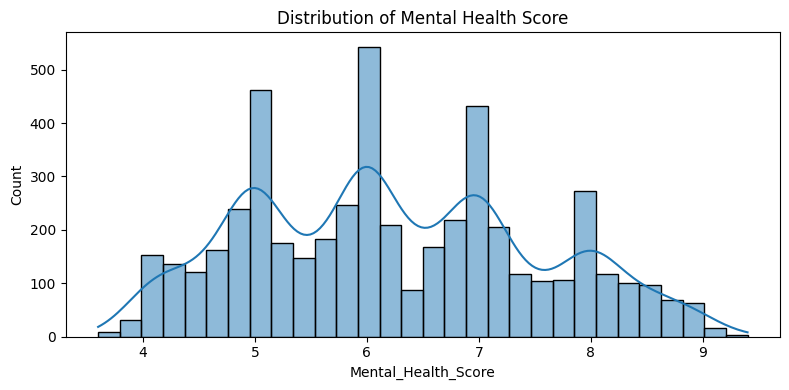

Takeaway: roughly bell-shaped, centred around 6.2, with a slight right tail.


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(students['Mental_Health_Score'], bins=30, kde=True, ax=ax)
ax.set_title('Distribution of Mental Health Score')
ax.set_xlabel('Mental_Health_Score')
plt.tight_layout()
plt.show()
print('Takeaway: roughly bell-shaped, centred around 6.2, with a slight right tail.')

### 4.2 Correlation Heatmap

Which numeric features are most correlated with the target?

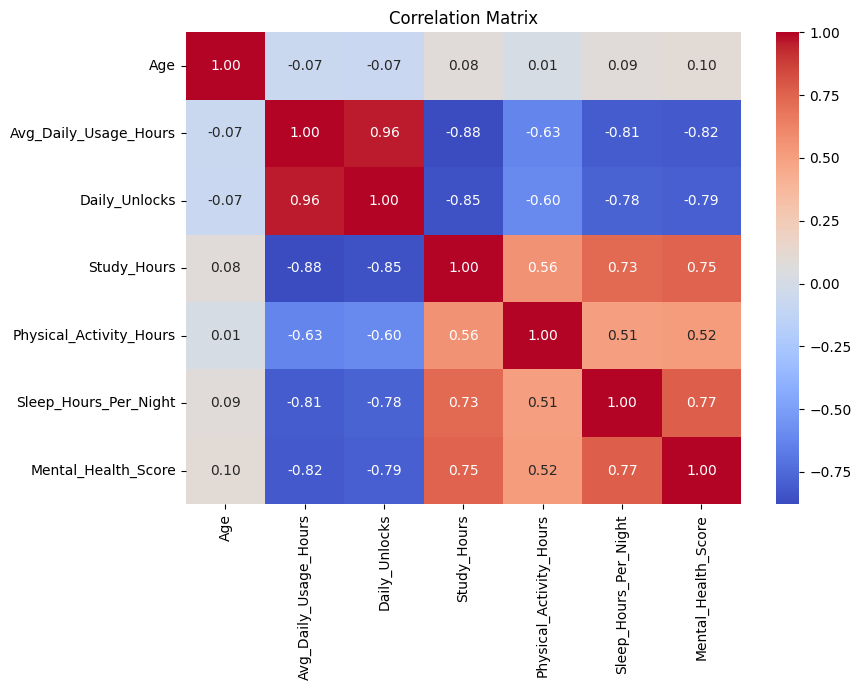

Takeaway: Sleep_Hours_Per_Night and Study_Hours have the strongest positive correlation; Avg_Daily_Usage_Hours is negatively correlated with the target.


In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = students[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title('Correlation Matrix')
plt.tight_layout()
plt.show()
print('Takeaway: Sleep_Hours_Per_Night and Study_Hours have the strongest positive correlation;'
      ' Avg_Daily_Usage_Hours is negatively correlated with the target.')

### 4.3 Stress Level vs Score

Does higher stress correspond to a lower score?

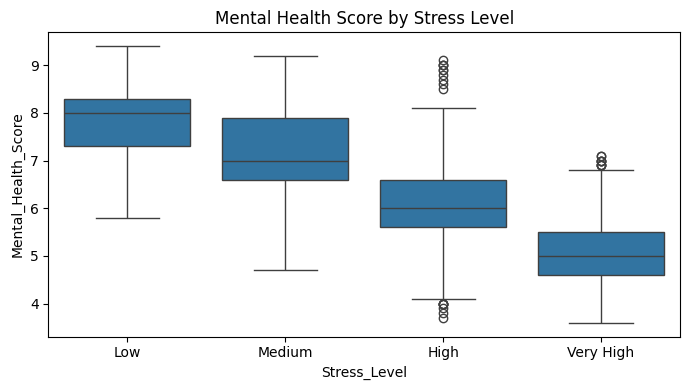

Takeaway: median score drops clearly at each step from Low to Very High.


In [ ]:
stress_order = ['Low', 'Medium', 'High', 'Very High']
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(
    data=students, x='Stress_Level', y='Mental_Health_Score',
    order=stress_order, ax=ax
)
ax.set_title('Mental Health Score by Stress Level')
plt.tight_layout()
plt.show()
print('Takeaway: median score drops clearly at each step from Low to Very High.')

### 4.4 Daily Usage Hours vs Score

Is more social media usage linked to a lower score?

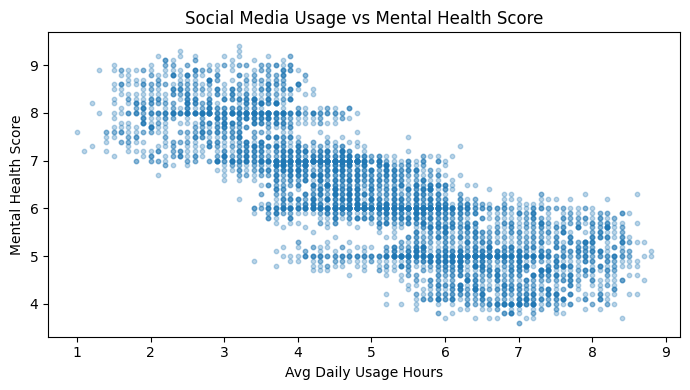

Takeaway: mild negative trend — higher daily usage is associated with slightly lower scores.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(
    students['Avg_Daily_Usage_Hours'], students['Mental_Health_Score'],
    alpha=0.3, s=10
)
ax.set_xlabel('Avg Daily Usage Hours')
ax.set_ylabel('Mental Health Score')
ax.set_title('Social Media Usage vs Mental Health Score')
plt.tight_layout()
plt.show()
print('Takeaway: mild negative trend — higher daily usage is associated with slightly lower scores.')

### 4.5 Sleep Hours vs Score

More sleep = better score?

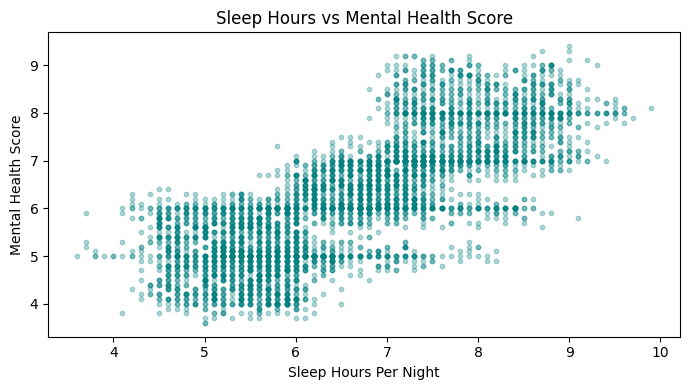

Takeaway: clear positive trend — more sleep is consistently linked to a higher score.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(
    students['Sleep_Hours_Per_Night'], students['Mental_Health_Score'],
    alpha=0.3, s=10, color='teal'
)
ax.set_xlabel('Sleep Hours Per Night')
ax.set_ylabel('Mental Health Score')
ax.set_title('Sleep Hours vs Mental Health Score')
plt.tight_layout()
plt.show()
print('Takeaway: clear positive trend — more sleep is consistently linked to a higher score.')

## 5. Skewness Check

I compute skewness for all numeric feature columns and decide based on the actual values which ones need a log1p transform.

In [ ]:
skew_vals = students[feature_num_cols].skew().sort_values(ascending=False)
print('Skewness values (feature columns only):')
print(skew_vals.round(3))

Skewness values (feature columns only):
Study_Hours                0.436
Age                        0.155
Sleep_Hours_Per_Night      0.124
Physical_Activity_Hours    0.053
Avg_Daily_Usage_Hours      0.006
Daily_Unlocks              0.002
dtype: float64


In [ ]:
# All values are below |0.5|. Study_Hours has the highest at ~0.44,
# so I apply log1p to it as a precaution for the linear baseline.
# Everything else is close enough to symmetric to scale directly.
skewed_features    = ['Study_Hours']
plain_num_features = [
    'Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
    'Physical_Activity_Hours', 'Sleep_Hours_Per_Night'
]
print('Skewed features (log1p):', skewed_features)
print('Plain numeric:', plain_num_features)

Skewed features (log1p): ['Study_Hours']
Plain numeric: ['Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night']


## 6. Train / Test Split (80 / 20)

I split first — before any fitting — to prevent leakage. The country grouping step that follows uses only the training set.

In [ ]:
ordinal_features = ['Stress_Level']
nominal_features = [
    'Gender', 'Academic_Level', 'Most_Used_Platform',
    'Purpose_Of_Use', 'Country'
]

all_features = skewed_features + plain_num_features + ordinal_features + nominal_features

X = students[all_features].copy()
y = students['Mental_Health_Score']

train_X, test_X, train_y, test_y = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
print(f'Training set: {train_X.shape}, Test set: {test_X.shape}')

Training set: (3998, 12), Test set: (1000, 12)


## 7. Feature Engineering — Country Grouping

Country has 111 unique values; one-hot encoding all of them adds noisy columns. I keep the top 10 most frequent countries from the **training set** and label everything else "Other". Computing the top-10 list from training data only prevents leakage.

In [ ]:
# Top countries derived from training data only
top_countries = train_X['Country'].value_counts().index[:10].tolist()
print('Top 10 countries (training set):', top_countries)

def bucket_country(series, top):
    return series.where(series.isin(top), other='Other')

train_X = train_X.copy()
test_X  = test_X.copy()

train_X['Country'] = bucket_country(train_X['Country'], top_countries)
test_X['Country']  = bucket_country(test_X['Country'],  top_countries)

print('\nCountry counts in training set after grouping:')
print(train_X['Country'].value_counts())

Top 10 countries (training set): ['Other', 'India', 'USA', 'Canada', 'Australia', 'UK', 'Germany', 'Mexico', 'France', 'Turkey']

Country counts in training set after grouping:
Country
Other        2594
India         303
USA           280
Canada        184
Australia     155
UK            150
Germany       109
Mexico         75
France         74
Turkey         74
Name: count, dtype: int64


## 8. Preprocessing Pipeline

A single `ColumnTransformer` with four branches:
- **Skewed numeric** — median imputer → log1p → standard scaler
- **Other numeric** — median imputer → standard scaler
- **Stress_Level** — most-frequent imputer → ordinal encoder (Low < Medium < High < Very High)
- **Nominal categoricals** — most-frequent imputer → one-hot encoder

Every branch has an imputer so the pipeline is safe even if production data has missing values.

In [ ]:
skewed_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('log1p',  FunctionTransformer(np.log1p)),
    ('scale',  StandardScaler()),
])

numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale',  StandardScaler()),
])

ordinal_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OrdinalEncoder(categories=[['Low', 'Medium', 'High', 'Very High']])),
])

nominal_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

prep = ColumnTransformer(transformers=[
    ('skewed',  skewed_pipe,  skewed_features),
    ('numeric', numeric_pipe, plain_num_features),
    ('ordinal', ordinal_pipe, ordinal_features),
    ('nominal', nominal_pipe, nominal_features),
])

print('Preprocessor defined.')

Preprocessor defined.


## 9. Build Model Pipelines

Each model gets its own `Pipeline(prep + model)` so preprocessing is always bundled with the estimator.

In [ ]:
lr_pipe = Pipeline([
    ('prep',  prep),
    ('model', LinearRegression()),
])

rf_pipe = Pipeline([
    ('prep',  prep),
    ('model', RandomForestRegressor(random_state=SEED)),
])

xgb_pipe = Pipeline([
    ('prep',  prep),
    ('model', XGBRegressor(random_state=SEED, verbosity=0)),
])

hgb_pipe = Pipeline([
    ('prep',  prep),
    ('model', HistGradientBoostingRegressor(random_state=SEED)),
])

print('Four model pipelines created: LR, RF, XGB, HGB')

Four model pipelines created: LR, RF, XGB, HGB


## 10. Cross-Validation (Default Settings)

I run 5-fold CV on the training set for all four models with default hyperparameters to get a baseline before tuning.

In [ ]:

models = {
    "LinearRegression":     lr_pipe,
    "RandomForest":         rf_pipe,
    "XGBoost":              xgb_pipe,
    "HistGradientBoosting": hgb_pipe,
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["r2", "neg_root_mean_squared_error", "neg_mean_absolute_error",
           "neg_mean_absolute_percentage_error"]

cv_results = {}

for name, pipeline in models.items():
    print(f"Running cross-validation: {name}...")
    scores = cross_validate(pipeline, train_X, train_y, cv=cv, scoring=scoring,
                            n_jobs=-1, error_score="raise")
    cv_results[name] = {metric: scores[f"test_{metric}"].mean() for metric in scoring}

cv_df = pd.DataFrame(cv_results).T
cv_df.columns = ["R2", "RMSE", "MAE", "MAPE"]
cv_df[["RMSE", "MAE", "MAPE"]] *= -1
cv_df = cv_df.sort_values("R2", ascending=False)
print(cv_df.round(4))

Running cross-validation: LinearRegression...
Running cross-validation: RandomForest...
Running cross-validation: XGBoost...
Running cross-validation: HistGradientBoosting...
                          R2    RMSE     MAE    MAPE
RandomForest          0.8650  0.4637  0.3432  0.0582
XGBoost               0.8629  0.4671  0.3488  0.0590
HistGradientBoosting  0.8402  0.5044  0.3873  0.0657
LinearRegression      0.7206  0.6673  0.5257  0.0900


## 11. Hyperparameter Tuning

I tune the three non-baseline models with `RandomizedSearchCV` (cv=5, n_iter=15, scoring=r2). All parameter names are prefixed with `model__` to match the pipeline step name.

In [ ]:
rf_param_grid = {
    'model__n_estimators':      [200],
    'model__max_depth':         [10, 15, 20, None],
    'model__min_samples_leaf':  [1, 2, 4, 8],
    'model__max_features':      [0.3, 0.5, 0.7, 1.0],
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

rf_search = RandomizedSearchCV(
    rf_pipe, rf_param_grid, n_iter=15, cv=kf,
    scoring='r2', n_jobs=-1, verbose=1,
    random_state=42, return_train_score=True
)
rf_search.fit(train_X, train_y)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


RandomizedSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('prep',
                                              ColumnTransformer(transformers=[('skewed',
                                                                               Pipeline(steps=[('impute',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('log1p',
                                                                                                FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                                               ('scale',
                                                                                                StandardScaler())]),
                                                                               ['Study_Hours']),
                                                                              ('numeric',
                                                                               Pipeline(steps=[('impute',
                                                                                                SimpleImput...
                                                                                'Academic_Level',
                                                                                'Most_Used_Platform',
                                                                                'Purpose_Of_Use',
                                                                                'Country'])])),
                                             ('model',
                                              RandomForestRegressor(random_state=42))]),
                   n_iter=15, n_jobs=-1,
                   param_distributions={'model__max_depth': [10, 15, 20, None],
                                        'model__max_features': [0.3, 0.5, 0.7,
                                                                1.0],
                                        'model__min_samples_leaf': [1, 2, 4, 8],
                                        'model__n_estimators': [200]},
                   random_state=42, return_train_score=True, scoring='r2',
                   verbose=1)

In [ ]:
xgb_param_grid = {
    'model__n_estimators':     [300, 600],
    'model__max_depth':        [3, 5, 7],
    'model__learning_rate':    [0.03, 0.05, 0.1],
    'model__subsample':        [0.7, 0.85, 1.0],
    'model__colsample_bytree': [0.7, 1.0],
}

xgb_search = RandomizedSearchCV(
    xgb_pipe, xgb_param_grid, n_iter=25, cv=kf,
    scoring='r2', n_jobs=-1, verbose=1,
    random_state=42, return_train_score=True
)
xgb_search.fit(train_X, train_y)

Fitting 5 folds for each of 25 candidates, totalling 125 fits


RandomizedSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('prep',
                                              ColumnTransformer(transformers=[('skewed',
                                                                               Pipeline(steps=[('impute',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('log1p',
                                                                                                FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                                               ('scale',
                                                                                                StandardScaler())]),
                                                                               ['Study_Hours']),
                                                                              ('numeric',
                                                                               Pipeline(steps=[('impute',
                                                                                                SimpleImput...
                                                           multi_strategy=None,
                                                           n_estimators=None,
                                                           n_jobs=None,
                                                           num_parallel_tree=None, ...))]),
                   n_iter=25, n_jobs=-1,
                   param_distributions={'model__colsample_bytree': [0.7, 1.0],
                                        'model__learning_rate': [0.03, 0.05,
                                                                 0.1],
                                        'model__max_depth': [3, 5, 7],
                                        'model__n_estimators': [300, 600],
                                        'model__subsample': [0.7, 0.85, 1.0]},
                   random_state=42, return_train_score=True, scoring='r2',
                   verbose=1)

In [ ]:
hgb_param_grid = {
    'model__max_iter':          [300, 600],
    'model__learning_rate':     [0.05, 0.1],
    'model__max_leaf_nodes':    [31, 63],
    'model__min_samples_leaf':  [10, 20, 40],
    'model__l2_regularization': [0.0, 1.0],
}

hgb_search = RandomizedSearchCV(
    hgb_pipe, hgb_param_grid, n_iter=15, cv=kf,
    scoring='r2', n_jobs=-1, verbose=1,
    random_state=42, return_train_score=True
)
hgb_search.fit(train_X, train_y)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


RandomizedSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('prep',
                                              ColumnTransformer(transformers=[('skewed',
                                                                               Pipeline(steps=[('impute',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('log1p',
                                                                                                FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                                               ('scale',
                                                                                                StandardScaler())]),
                                                                               ['Study_Hours']),
                                                                              ('numeric',
                                                                               Pipeline(steps=[('impute',
                                                                                                SimpleImput...
                                                                                'Purpose_Of_Use',
                                                                                'Country'])])),
                                             ('model',
                                              HistGradientBoostingRegressor(random_state=42))]),
                   n_iter=15, n_jobs=-1,
                   param_distributions={'model__l2_regularization': [0.0, 1.0],
                                        'model__learning_rate': [0.05, 0.1],
                                        'model__max_iter': [300, 600],
                                        'model__max_leaf_nodes': [31, 63],
                                        'model__min_samples_leaf': [10, 20,
                                                                    40]},
                   random_state=42, return_train_score=True, scoring='r2',
                   verbose=1)

In [ ]:
tuned = {
    'RandomForest':         rf_search.best_estimator_,
    'XGBoost':              xgb_search.best_estimator_,
    'HistGradientBoosting': hgb_search.best_estimator_,
}

scoring = ['r2', 'neg_root_mean_squared_error', 'neg_mean_absolute_error',
           'neg_mean_absolute_percentage_error']

rows = {}
for name, m in tuned.items():
    s = cross_validate(m, train_X, train_y, cv=kf, scoring=scoring,
                       return_train_score=True, n_jobs=-1)
    rows[name] = {
        'train_R2': s['train_r2'].mean(),
        'val_R2':   s['test_r2'].mean(),
        'RMSE':     -s['test_neg_root_mean_squared_error'].mean(),
        'MAE':      -s['test_neg_mean_absolute_error'].mean(),
        'MAPE_%':   -s['test_neg_mean_absolute_percentage_error'].mean() * 100,
    }

df = pd.DataFrame(rows).T.sort_values('val_R2', ascending=False)
df['overfit_gap'] = df['train_R2'] - df['val_R2']
print(df.round(4))

                      train_R2  val_R2    RMSE     MAE  MAPE_%  overfit_gap
XGBoost                 0.9995  0.8848  0.4282  0.3156  5.3232       0.1147
HistGradientBoosting    0.9932  0.8803  0.4363  0.3205  5.4102       0.1129
RandomForest            0.9818  0.8718  0.4520  0.3362  5.6992       0.1100


## 12. Final Evaluation on the Test Set

I fit the baseline on the full training set, then evaluate all four models on the untouched test set. Train R2 vs Test R2 gap shows overfitting.

In [ ]:
final_models = {
    'RandomForest':         rf_search.best_estimator_,
    'XGBoost':              xgb_search.best_estimator_,
    'HistGradientBoosting': hgb_search.best_estimator_,
}

rows = {}
for name, m in final_models.items():
    train_pred = m.predict(train_X)
    test_pred  = m.predict(test_X)
    rows[name] = {
        'train_R2': r2_score(train_y, train_pred),
        'test_R2':  r2_score(test_y, test_pred),
        'RMSE':     np.sqrt(mean_squared_error(test_y, test_pred)),
        'MAE':      mean_absolute_error(test_y, test_pred),
        'MAPE_%':   mean_absolute_percentage_error(test_y, test_pred) * 100,
    }

final_df = pd.DataFrame(rows).T.sort_values('test_R2', ascending=False)
final_df['overfit_gap'] = final_df['train_R2'] - final_df['test_R2']
print(final_df.round(4))

                      train_R2  test_R2    RMSE     MAE  MAPE_%  overfit_gap
XGBoost                 0.9991   0.9047  0.4124  0.3023  5.0695       0.0944
HistGradientBoosting    0.9910   0.8967  0.4293  0.3121  5.2589       0.0942
RandomForest            0.9842   0.8949  0.4332  0.3210  5.4102       0.0893


## 13. Feature Importance — Top 10

I use permutation importance on the test set for the winning model to identify the most influential features.

                    Feature  Importance
2     Avg_Daily_Usage_Hours    0.654821
5     Sleep_Hours_Per_Night    0.192517
3             Daily_Unlocks    0.124098
9        Most_Used_Platform    0.058740
11                  Country    0.045775
0               Study_Hours    0.037809
1                       Age    0.029325
4   Physical_Activity_Hours    0.023064
10           Purpose_Of_Use    0.016120
6              Stress_Level    0.011405


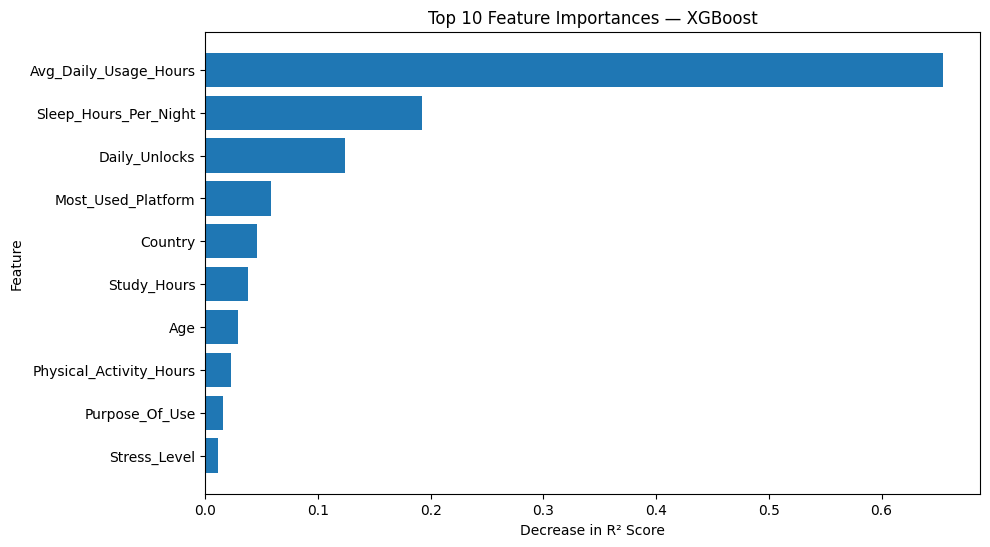

In [ ]:
from sklearn.inspection import permutation_importance

# Winner model
best_model = xgb_search.best_estimator_

perm_importance = permutation_importance(
    best_model,
    test_X,
    test_y,
    n_repeats=10,
    random_state=42,
    scoring='r2'
)

importance_df = pd.DataFrame({
    'Feature': test_X.columns,
    'Importance': perm_importance.importances_mean
})

top_10 = (
    importance_df
    .sort_values('Importance', ascending=False)
    .head(10)
)

print(top_10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10['Feature'],
    top_10['Importance']
)

plt.xlabel('Decrease in R² Score')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances — XGBoost')

plt.gca().invert_yaxis()
plt.show()

## 14. Save and Reload the Best Model

I save the winning tuned pipeline and reload it to verify it predicts correctly on 3 held-out rows.

In [ ]:

joblib.dump(best_model, "mental_health_pipeline.joblib")
files.download("mental_health_pipeline.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
loaded_model = joblib.load("mental_health_pipeline.joblib")

sample_rows = test_X.iloc[:2]
sample_true = test_y.iloc[:2].values
sample_pred = loaded_model.predict(sample_rows)

print('Reload verification on 3 test rows:')
for i, (true, pred) in enumerate(zip(sample_true, sample_pred)):
    print(f'  Row {i}: actual = {true:.2f}, predicted = {pred:.2f}')

Reload verification on 3 test rows:
  Row 0: actual = 5.30, predicted = 5.17
  Row 1: actual = 5.80, predicted = 5.57


In [ ]:
print(test_X.columns.tolist())

['Study_Hours', 'Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night', 'Stress_Level', 'Gender', 'Academic_Level', 'Most_Used_Platform', 'Purpose_Of_Use', 'Country']


## 15. Conclusion

Machine learning models can predict the mental health score from students' usage habits and lifestyle with good accuracy. Among the three tuned models, **XGBoost performed best**, with a test R² of 0.9047, RMSE of 0.4124, MAE of 0.3023, and MAPE of 5.07%. HistGradientBoosting and RandomForest were close behind.

Feature importance analysis shows the predictions are driven mainly by behavioral variables. **Average daily usage hours** is the strongest predictor by a wide margin, followed by **sleep hours per night** and **daily phone unlocks**. Platform, country, study hours, and age contribute less, and stress level has the lowest importance of the top ten. This suggests screen-use and sleep patterns carry most of the predictive signal in this dataset.

The gap between training R² (about 0.99) and test R² (0.90) shows some overfitting, although test performance matched cross-validation (about 0.885), so the model generalizes reliably. Stronger regularization is a possible next step.

Limitations: the data is observational survey data, so these results show associations, not causes. Performance on other populations or on real-world data may differ. Future work could add stronger regularization and validation on an independent dataset.